# ORCHID tutorial 04: Drift-diffusion: diodes, solar cells and OLEDs

**Goals.** Use the coupled-Newton drift–diffusion (DD) solver for single-carrier diodes (SCLC), solar
cells and OLEDs, and for multilayer heterostructures.

### Theory
In 1D, ORCHID solves

$$\frac{d}{dx}\!\left(\varepsilon\frac{d\psi}{dx}\right) = -q(p-n+N_D-N_A),\qquad
\frac{1}{q}\frac{dJ_n}{dx}=R-G,\qquad -\frac{1}{q}\frac{dJ_p}{dx}=R-G,$$

with $J_n=q\mu_n nF+qD_n n'$. Here $D=g_3\mu k_BT/q$, the recombination is Langevin,
$R=\gamma(np-n_i^2)$ with $\gamma=q(\mu_n+\mu_p)/\varepsilon$, and fluxes use Scharfetter–Gummel discretisation.

The Mott–Gurney limit is $J=\tfrac98\varepsilon\mu V^2/L^3$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (5.4, 3.6), "axes.grid": True, "grid.alpha": 0.3})
import orchid
print("ORCHID", orchid.__version__)

ORCHID 0.4.0


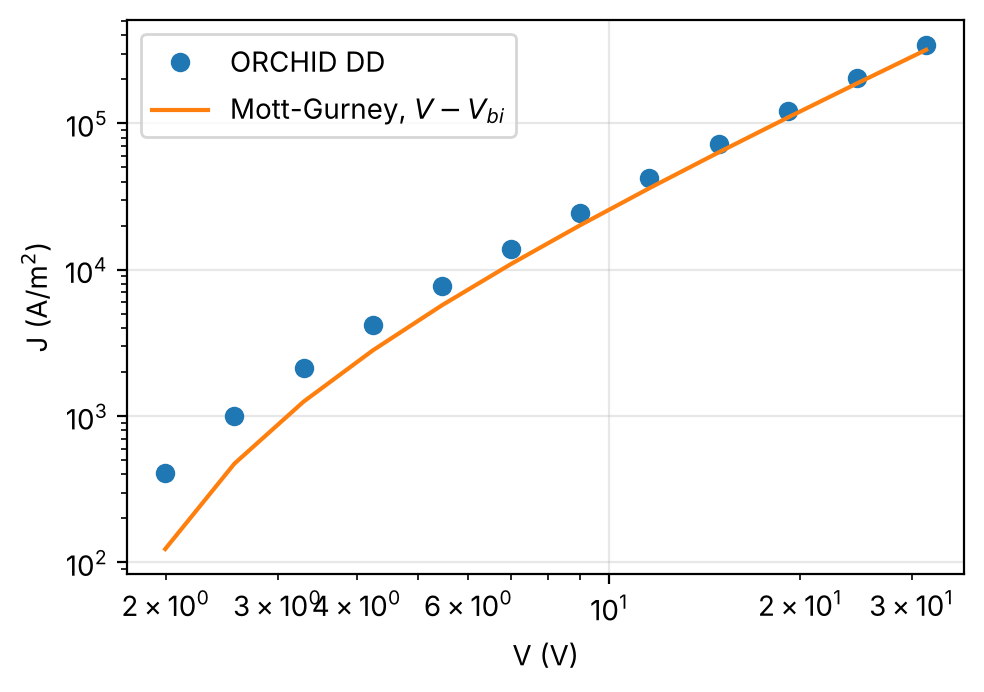

In [2]:
from orchid.drift_diffusion import Device, mott_gurney
mu, L = 1e-8, 100e-9
d = Device(L=L, N=201, Eg=2.4, phi_anode_p=0.0, phi_cathode_n=1.0, mu_n=1e-14, mu_p=mu,
           recombination=False)
V = np.logspace(0.3, 1.5, 12)
J = d.jv(V)["J"]
Vbi = 1.4
plt.loglog(V, J, "o", label="ORCHID DD")
plt.loglog(V, mott_gurney(V - Vbi, L, 3.5, mu), "-", label=r"Mott-Gurney, $V-V_{bi}$")
plt.xlabel("V (V)"); plt.ylabel(r"J (A/m$^2$)"); plt.legend();

### Organic solar cell
The open-circuit voltage follows Koster *et al.* (APL 86, 123509): $V_{oc}=\frac{E_g}{q}-\frac{kT}{q}\ln\frac{(1-P)\gamma N_c^2}{PG}$.

slope / (kT/e): 1.0004953925194182


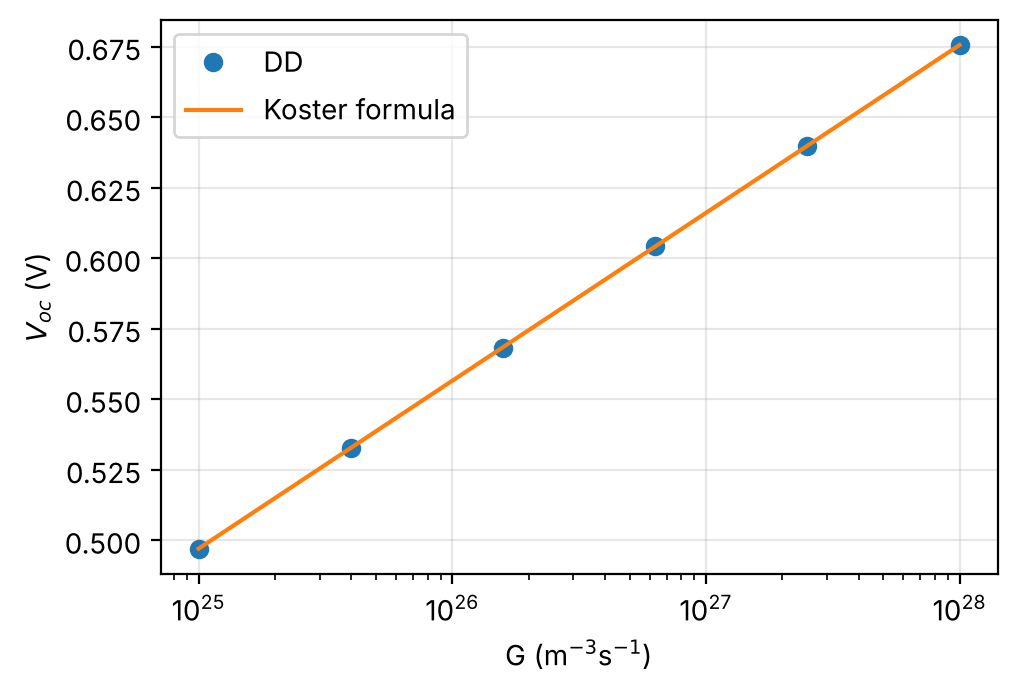

In [3]:
from orchid.drift_diffusion import pv_metrics, koster_voc
Gs = np.logspace(25, 28, 6)
Voc, Vk = [], []
for G in Gs:
    dev = Device(L=100e-9, N=161, Eg=1.2, mu_n=1e-8, mu_p=1e-8, phi_anode_p=0.1, phi_cathode_n=0.1, G=G)
    r = dev.jv(np.linspace(0, 0.9, 37))
    Voc.append(pv_metrics(r["V"], r["J"])["Voc"])
    gam = 1.602e-19 * 2e-8 / (3.5 * 8.854e-12)
    Vk.append(koster_voc(1.2, 300.0, dev.Nc, gam, G))
plt.semilogx(Gs, Voc, "o", label="DD"); plt.semilogx(Gs, Vk, "-", label="Koster formula")
plt.xlabel(r"G (m$^{-3}$s$^{-1}$)"); plt.ylabel(r"$V_{oc}$ (V)"); plt.legend()
print("slope / (kT/e):", np.polyfit(np.log(Gs), Voc, 1)[0] / 0.025852)

### OLED with emission zone and roll-off (continuum excitons)

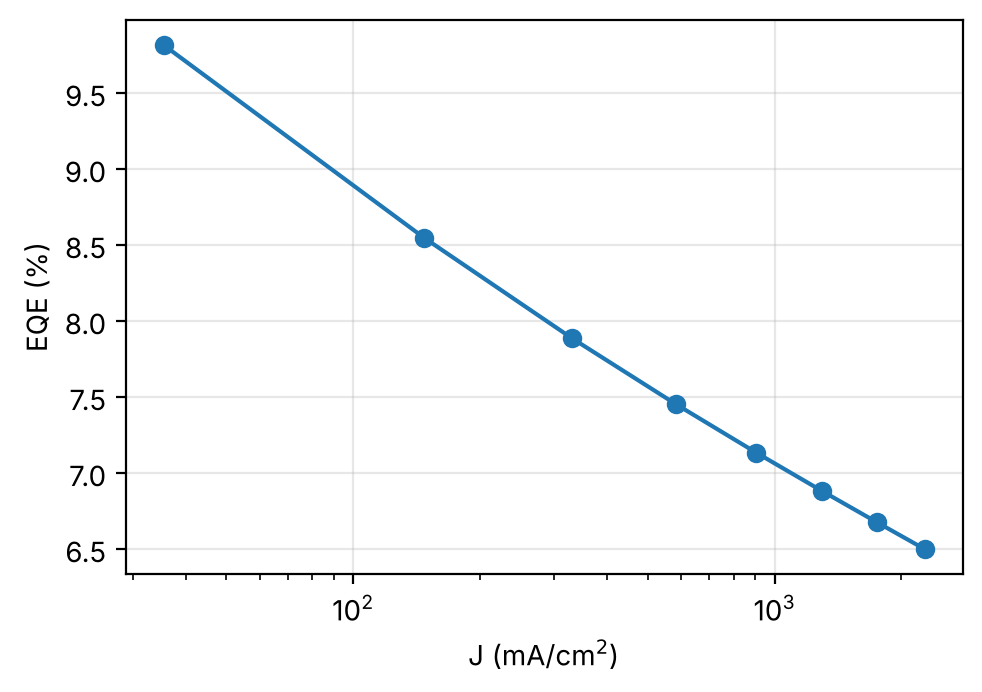

In [4]:
from orchid.devices import simulate_oled
dev = Device(L=100e-9, Eg=2.6, mu_n=1e-9, mu_p=1e-8, phi_anode_p=0.1, phi_cathode_n=0.1)
out = simulate_oled(dev, np.linspace(2.8, 9, 8), eta_ST=1.0, qPL=0.9, kSS=1e-17, kSP=1e-18)
plt.semilogx(np.array(out["J"]) / 10, 100 * np.array(out["EQE"]), "o-")
plt.xlabel(r"J (mA/cm$^2$)"); plt.ylabel("EQE (%)");

### Multilayer heterostructures
`MultilayerDevice` takes a list of layers, each with its own $E_g$, $\chi$, $\varepsilon_r$ and mobilities.
Band offsets appear at the interfaces. V19 validates it against NIST Sesame to $3\times10^{-6}$.

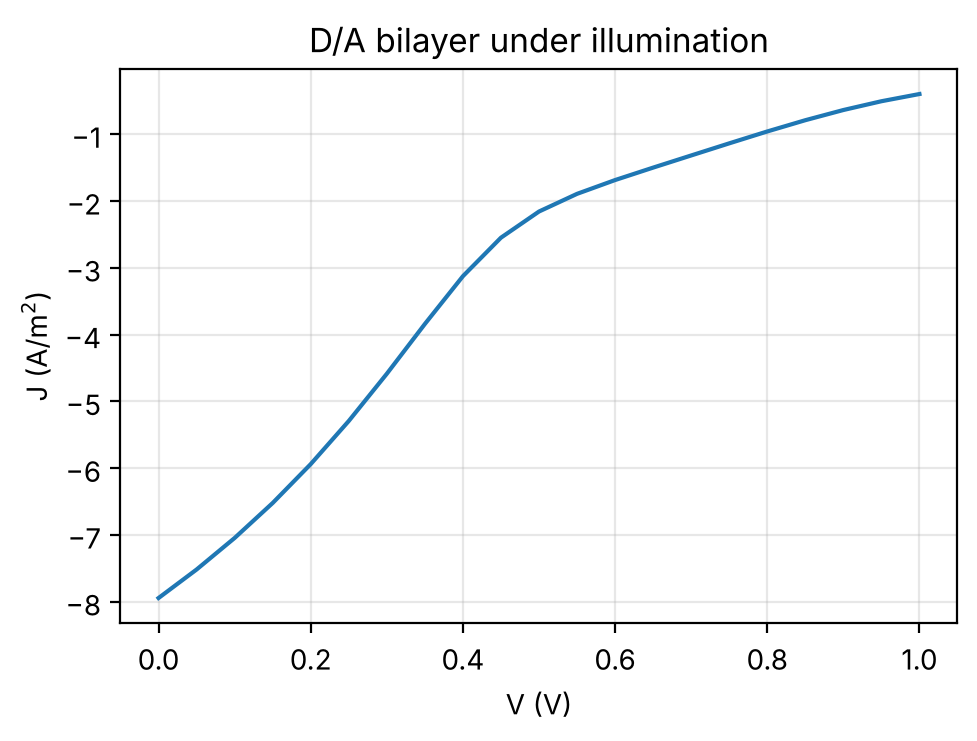

In [5]:
from orchid.drift_diffusion import MultilayerDevice
layers = [dict(d=50e-9, Eg=1.9, chi=3.0, eps_r=3.5, mu_n=1e-9, mu_p=1e-8, Nc=2.5e26, Nv=2.5e26, G=1e27),
          dict(d=50e-9, Eg=1.9, chi=3.8, eps_r=3.8, mu_n=1e-8, mu_p=1e-9, Nc=2.5e26, Nv=2.5e26, G=1e27)]
m = MultilayerDevice(layers, W_anode=4.8, W_cathode=3.9, nodes_per_layer=60, recombination=False,
                     srh=dict(Nt=1e21, midgap=True, Cn=1e-15, Cp=1e-15, charged=False))
r = m.jv(np.linspace(0, 1.0, 21))
plt.plot(r["V"], r["J"]); plt.xlabel("V (V)"); plt.ylabel(r"J (A/m$^2$)"); plt.title("D/A bilayer under illumination");

**Exercise.** Halve the Langevin prefactor (`langevin_prefactor=0.5`) in the solar-cell example. How does $V_{oc}$ change?

<details><summary>Solution</summary>

$V_{oc}$ rises by $(kT/q)\ln 2\approx 18$ mV, because $V_{oc}$ depends on $\ln\gamma$.
</details>

## Quiz

Five questions on this section. Run the cell to see them, then grade yourself with
`quiz("04", answers="abcda")` (one letter per question). The same quiz runs in a terminal
with `orchid quiz 04`.

In [6]:
from orchid.tutorials import quiz
quiz("04")

Quiz 04: Drift-diffusion: diodes, solar cells and OLEDs

Q1. Why is the Scharfetter-Gummel discretisation used for the current between two nodes?
    (a) It is second-order accurate in h
    (b) It uses the exact exponential solution of J between nodes, so it stays stable for large potential steps
    (c) It avoids solving Poisson's equation
    (d) It conserves energy

Q2. The trap-free space-charge-limited current (Mott-Gurney) is
    (a) J = 9/8 eps mu V^2 / L^3
    (b) J = eps mu V / L^2
    (c) J = 9/8 eps mu V / L^3
    (d) J = q n mu V / L

Q3. Koster et al. (2005) predict that Voc depends on the light intensity (generation G) as
    (a) dVoc/dln G = kT/e for bimolecular (Langevin) recombination
    (b) dVoc/dln G = Eg/e
    (c) Voc is independent of G
    (d) dVoc/dln G = 2kT/e

Q4. The Langevin recombination coefficient is
    (a) gamma = kT mu / q
    (b) gamma = eps / (q mu)
    (c) gamma = q (mu_n + mu_p) / eps
    (d) gamma = q mu_n mu_p / eps

Q5. For the metal-insulator-

In [7]:
# replace with your answers, e.g. "abcda"
# quiz("04", answers=".....")

<details><summary>Answer key</summary>

`baacc`. Run `quiz("04", answers="baacc")` to see the explanation for every question.
</details>

---
[Tutorial index](README.md) · ORCHID documentation · `orchid tutorials`